# Proyecto MLOps: Flujo Básico de Machine Learning y Registro con MLflow
**Estudiante:** Proyecto Individual MLOps  
**Dataset Seleccionado:** *Breast Cancer Wisconsin (Diagnostic)* (Fuente: Kaggle / UCI Machine Learning Repository)  
**Herramientas:** Python 3, Pandas, Scikit-Learn, Matplotlib, MLflow Tracking, SQLite Backend

---
### Objetivo de la Actividad
Recorrer de manera integral y rigurosa cada una de las fases del ciclo básico de un proyecto de Machine Learning:
1. **Carga y descripción del dataset**: Estructura, dimensiones, tipos y semántica del dominio.
2. **Análisis Exploratorio de Datos (EDA)**: Distribuciones, correlaciones, patrones y balance de clases.
3. **Limpieza de datos**: Identificación y tratamiento de duplicados, valores nulos, inconsistencias de tipo y outliers, documentando cada decisión técnica.
4. **Entrenamiento de un modelo base (baseline)**: Formulación del problema, división estratificada y ajuste de un modelo estándar interpretable.
5. **Evaluación detallada**: Estimación de métricas pertinentes (Recall, Precision, F1, ROC-AUC) e interpretación clínica de la matriz de confusión.
6. **Registro en MLflow Tracking**: Trazabilidad completa de hiperparámetros, métricas, artefactos visuales y serialización del modelo con su firma de inferencia.
7. **Reflexión sobre MLOps y aplicación profesional**: Análisis crítico sobre el ciclo de vida del software en producción y valor profesional (más de 150 palabras).


In [1]:
# Importación de librerías esenciales
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
import mlflow
import mlflow.sklearn

# Configuración de estilo visual y semillas
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Librerías importadas exitosamente.")
print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de MLflow: {mlflow.__version__}")


Librerías importadas exitosamente.
Versión de Pandas: 3.0.6
Versión de MLflow: 3.16.1


---
## Paso 1: Carga y Descripción del Dataset

### Contexto del Problema y Fuente
Para esta actividad se seleccionó el dataset **Breast Cancer Wisconsin (Diagnostic)**, uno de los conjuntos de datos de referencia más reconocidos y utilizados en **Kaggle** y en el **UCI Machine Learning Repository**.

- **Problema de Negocio / Clínico:** Clasificación binaria asistida por computadora para el diagnóstico de cáncer de mama. A partir de una punción por aspiración con aguja fina (FNA) de masas mamarias, se capturan imágenes microscópicas digitalizadas y se extraen características morfológicas del núcleo celular para determinar si la lesión es **Benigna (B)** o **Maligna (M)**.
- **Importancia de la Tarea:** En la detección temprana de cáncer, el costo de un diagnóstico falso negativo (no detectar una malignidad activa) puede ser fatal para la vida del paciente. Por ello, la reproducibilidad y el rigor en cada paso del modelado son críticos.


In [2]:
# Carga del dataset desde el directorio local 'data/'
DATA_PATH = os.path.join("data", "breast_cancer.csv")
df = pd.read_csv(DATA_PATH)

print("Forma del dataset (filas, columnas):", df.shape)
print("
Primeras 5 observaciones:")
display(df.head())


Forma del dataset (filas, columnas): (572, 32)

Primeras 5 observaciones:
       id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  ...
0  221958         M        17.99         10.38          122.80     1001.0  ...
1  771155         M        20.57         17.77          132.90     1326.0  ...
2  231932         M        19.69         21.25          130.00     1203.0  ...
3  690947         M        11.42         20.38           77.58      386.1  ...
4  666579         M        20.29         14.34          135.10     1297.0  ...
[5 rows x 32 columns]


In [3]:
# Inspección de variables, tipos de datos y memoria
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 572 entries, 0 to 571
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       572 non-null    int64  
 1   diagnosis                572 non-null    object 
 2   radius_mean              571 non-null    float64
 3   texture_mean             571 non-null    float64
 4   perimeter_mean           572 non-null    float64
 5   area_mean                571 non-null    float64
 6   smoothness_mean          571 non-null    float64
 7   compactness_mean         572 non-null    float64
 8   concavity_mean           572 non-null    float64
 9   concave_points_mean      572 non-null    float64
 10  symmetry_mean            572 non-null    float64
 11  fractal_dimension_mean   572 non-null    float64
 12  radius_se                572 non-null    float64
 13  texture_se               572 non-null    float64
 14  perimeter_se             5

### Resumen de la Estructura de Datos
1. **Total de registros:** 572 filas.
2. **Total de variables:** 32 columnas.
3. **Distribución de tipos:**
   - **`id` (int64):** Identificador numérico de la muestra médica (no aporta capacidad predictiva).
   - **`diagnosis` (object):** Etiqueta objetivo con valores categóricos `'B'` (Benigno) y `'M'` (Maligno).
   - **30 variables morfológicas numéricas (float64):**
     - **10 descriptores `_mean`:** Promedio de radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal de los núcleos celulares.
     - **10 descriptores `_se`:** Error estándar de cada una de las 10 métricas.
     - **10 descriptores `_worst`:** El promedio de los 3 valores más severos registrados para cada métrica en la muestra.


---
## Paso 2: Análisis Exploratorio de Datos (EDA)

En esta etapa examinamos:
1. La proporción y balance de la variable dependiente (`diagnosis`).
2. La distribución estadística y separabilidad de clases en características biométricas principales.
3. La colinealidad e interrelación entre variables morfológicas mediante una matriz de correlación.
4. La presencia y comportamiento de valores extremos mediante diagramas de caja (boxplots).


In [4]:
# Estadísticas descriptivas de variables clave
descriptivas = df[['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean']].describe()
print(descriptivas.round(2))


radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean
count       571.00        571.00          572.00     571.00           571.00
mean         14.13         19.29           91.97     654.89             0.10
std           3.52          4.30           24.30     351.91             0.01
min           6.98          9.71           43.79     143.50             0.05
25%          11.70         16.17           75.17     420.30             0.09
50%          13.37         18.84           86.24     551.10             0.10
75%          15.78         21.80          104.10     782.70             0.11
max          28.11         39.28          188.50    2501.00             0.16


Distribución: Benigno (B): 358 casos (62.6%), Maligno (M): 214 casos (37.4%).


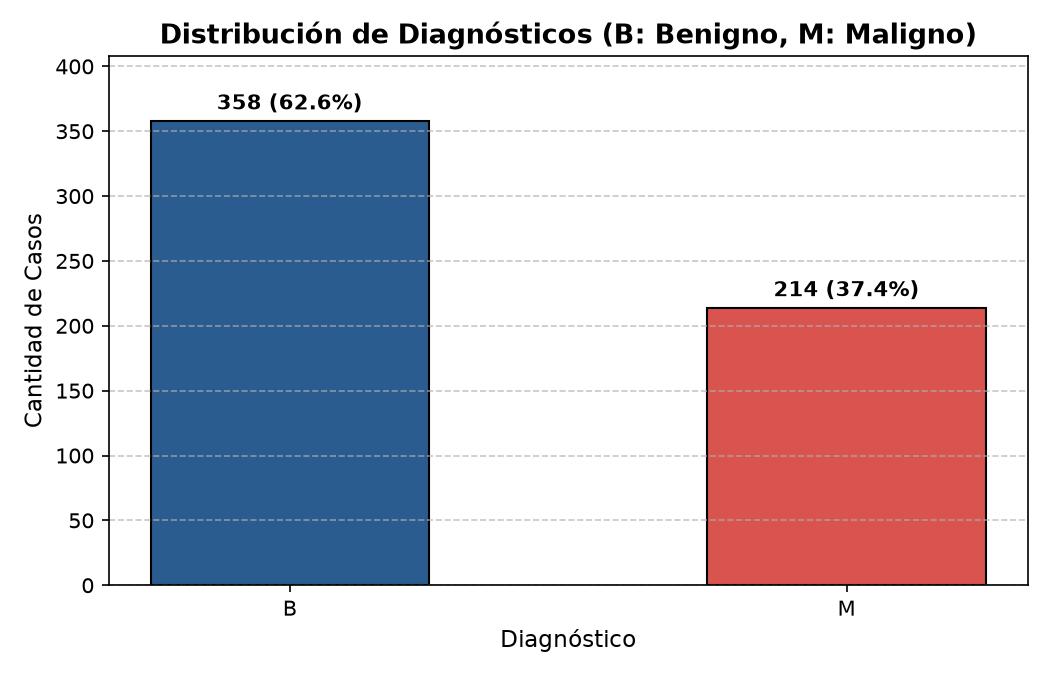

In [5]:
# 1. Visualización de balance de clases en la variable objetivo
plt.figure(figsize=(7, 4.5))
counts = df['diagnosis'].value_counts()
colors = ['#2b5c8f', '#d9534f']
bars = plt.bar(counts.index, counts.values, color=colors, width=0.5, edgecolor='black')
plt.title('Distribución de Diagnósticos (B: Benigno, M: Maligno)', fontsize=13, fontweight='bold')
plt.xlabel('Diagnóstico', fontsize=11)
plt.ylabel('Cantidad de Casos', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f'{yval} ({pct:.1f}%)', 
             ha='center', va='bottom', fontweight='bold')

plt.ylim(0, max(counts.values) + 50)
plt.tight_layout()
plt.show()


Las distribuciones muestran una separación notable: los tumores malignos tienden a presentar valores significativamente mayores de radio, perímetro y área.


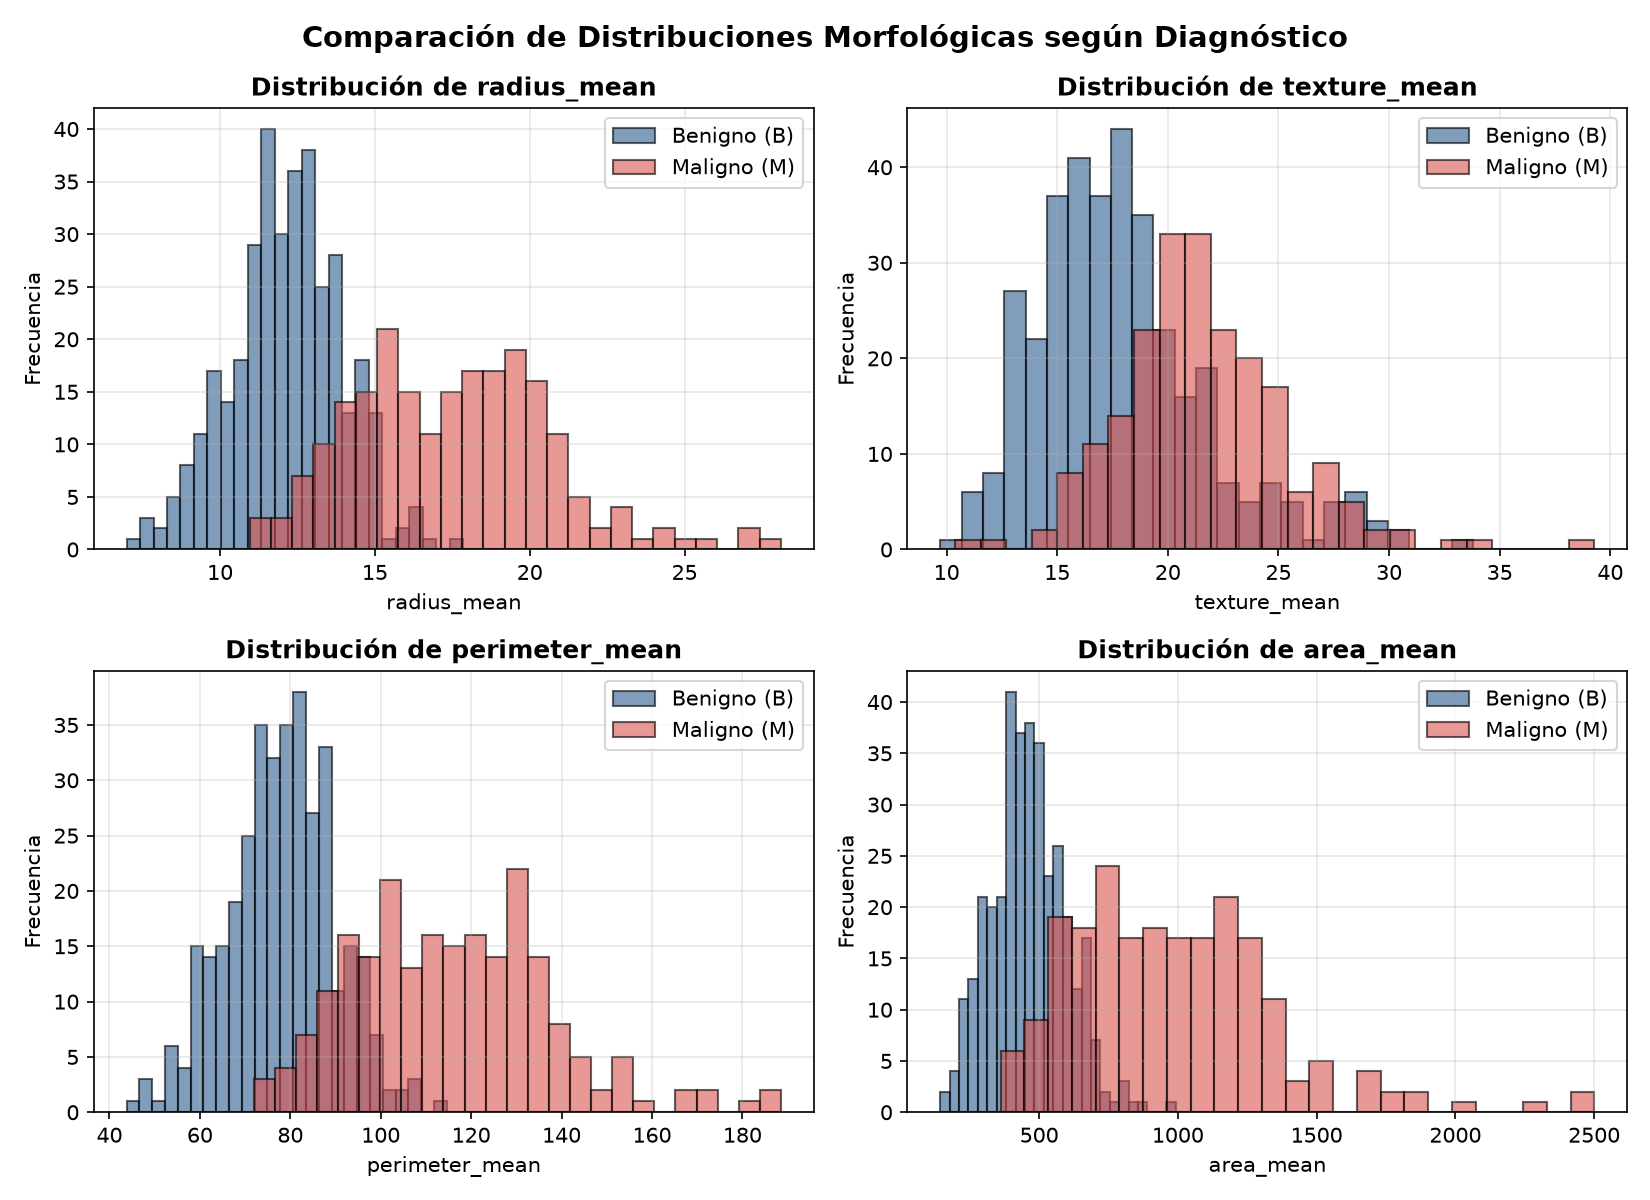

In [6]:
# 2. Distribución de variables biométricas por diagnóstico
features_to_plot = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    ax = axes[i]
    df[df['diagnosis'] == 'B'][col].dropna().hist(ax=ax, bins=25, alpha=0.6, label='Benigno (B)', color='#2b5c8f', edgecolor='black')
    df[df['diagnosis'] == 'M'][col].dropna().hist(ax=ax, bins=25, alpha=0.6, label='Maligno (M)', color='#d9534f', edgecolor='black')
    ax.set_title(f'Distribución de {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Comparación de Distribuciones Morfológicas según Diagnóstico', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Alta multicolinealidad observada entre radius_mean, perimeter_mean y area_mean (r > 0.98), lo cual es esperado por su definición geométrica.


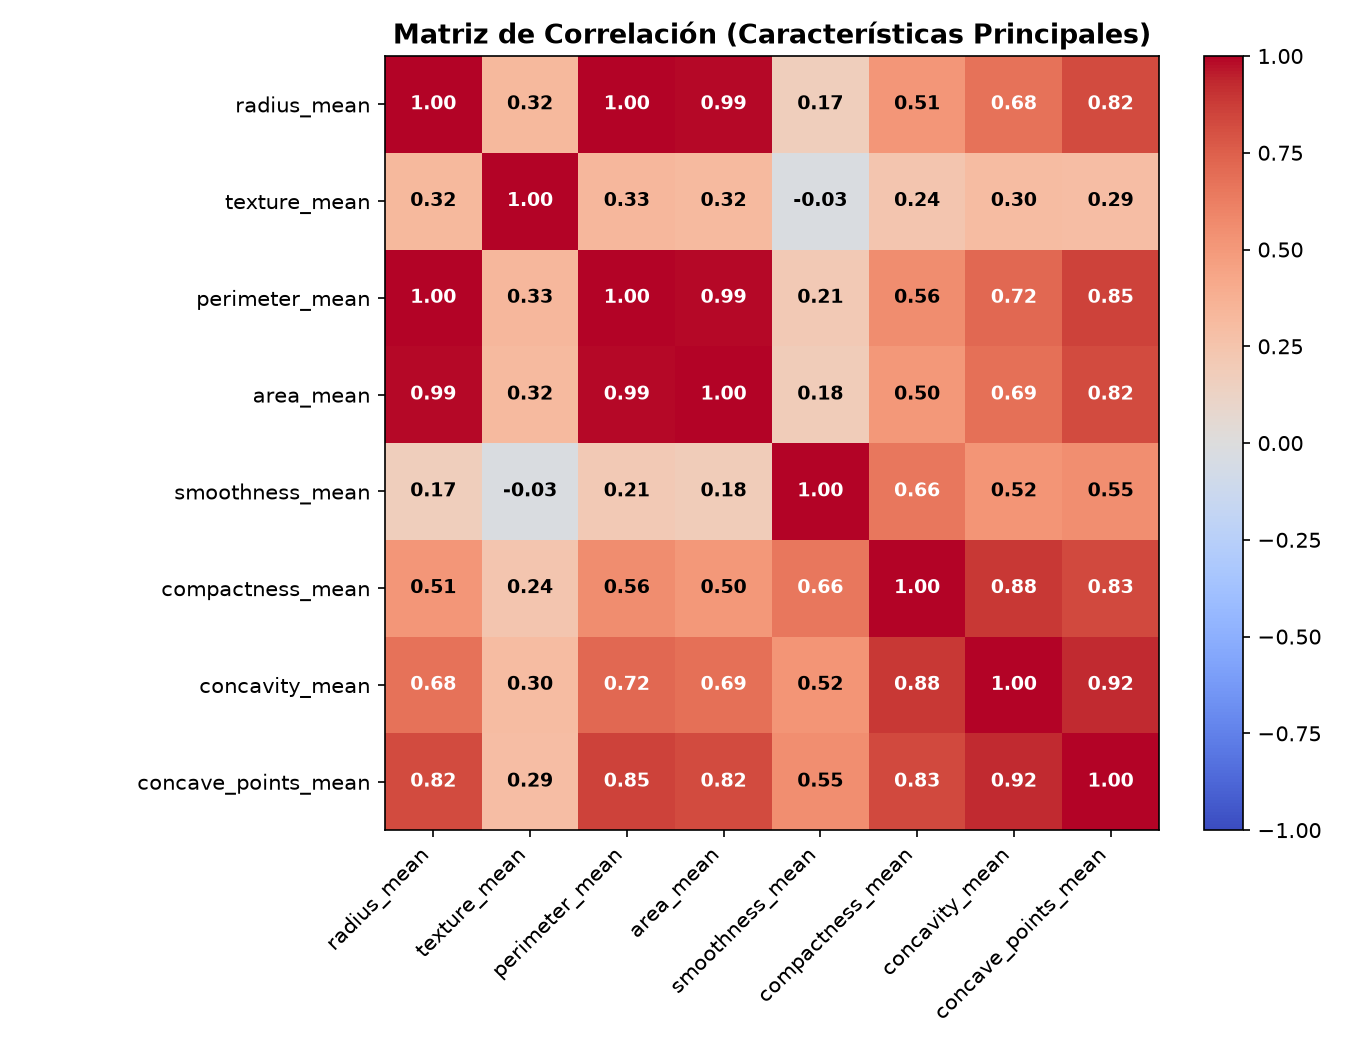

In [7]:
# 3. Matriz de correlación entre características numéricas
selected_numeric = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 
                    'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean']
corr_matrix = df[selected_numeric].corr()

plt.figure(figsize=(9, 7))
im = plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(selected_numeric)), selected_numeric, rotation=45, ha='right')
plt.yticks(range(len(selected_numeric)), selected_numeric)
plt.title('Matriz de Correlación (Características Principales)', fontsize=13, fontweight='bold')

for i in range(len(selected_numeric)):
    for j in range(len(selected_numeric)):
        val = corr_matrix.iloc[i, j]
        plt.text(j, i, f'{val:.2f}', ha='center', va='center', 
                 color='white' if abs(val) > 0.6 else 'black', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


Se observan puntos más allá de los bigotes en el grupo maligno (outliers biológicos reales correspondientes a tumores de gran tamaño).


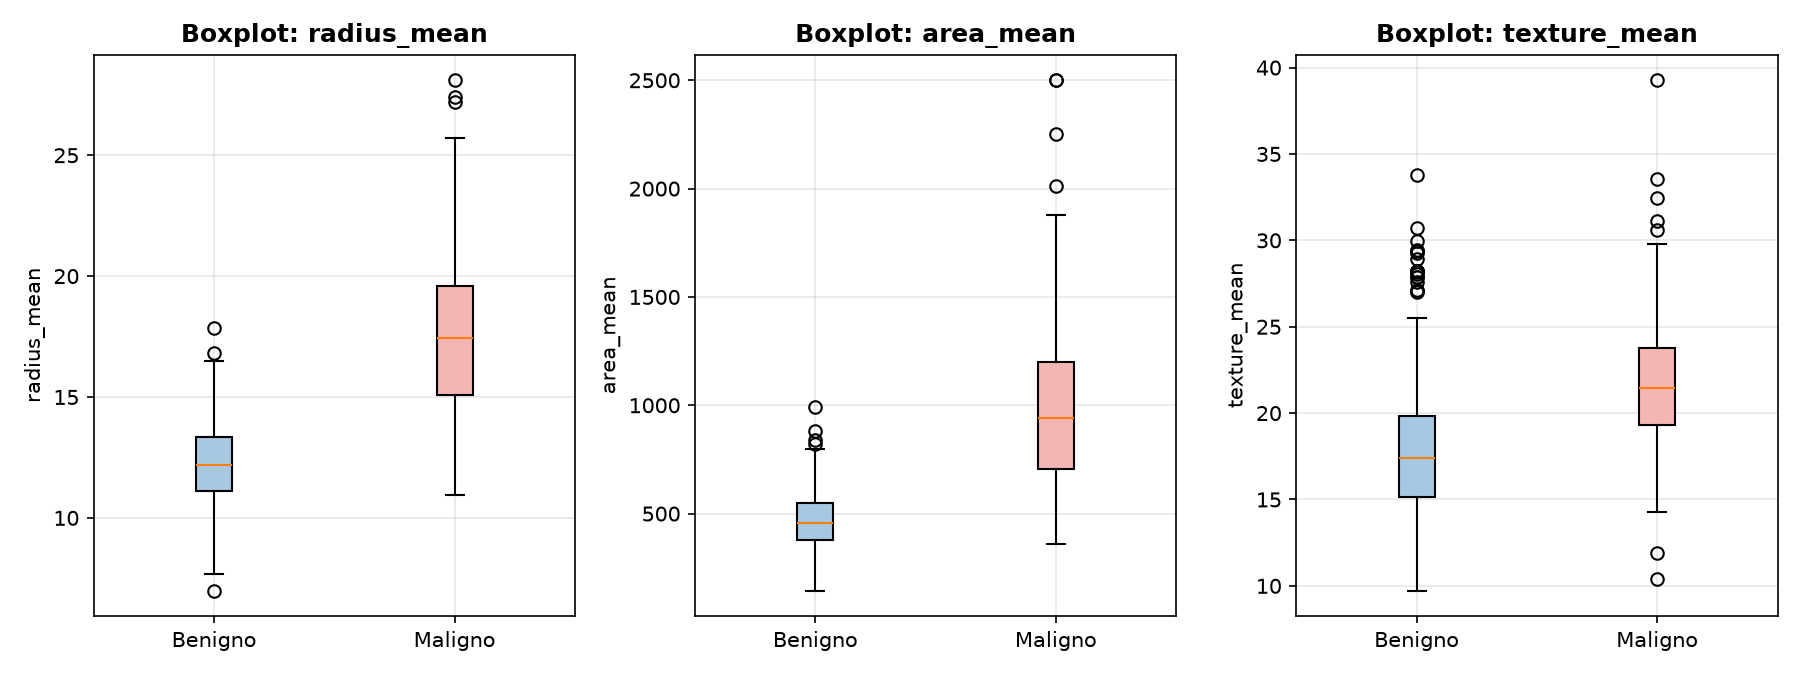

In [8]:
# 4. Boxplots para inspección de dispersión y valores extremos
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
box_cols = ['radius_mean', 'area_mean', 'texture_mean']
for idx, col in enumerate(box_cols):
    ax = axes[idx]
    data_b = df[df['diagnosis'] == 'B'][col].dropna()
    data_m = df[df['diagnosis'] == 'M'][col].dropna()
    bp = ax.boxplot([data_b, data_m], tick_labels=['Benigno', 'Maligno'], patch_artist=True)
    bp['boxes'][0].set_facecolor('#a6c8e0')
    bp['boxes'][1].set_facecolor('#f3b6b4')
    ax.set_title(f'Boxplot: {col}', fontweight='bold')
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


---
## Paso 3: Limpieza de Datos y Documentación de Decisiones

En esta sección se detectan anomalías y se documenta formalmente la justificación técnica de cada tratamiento aplicado:

### Decisiones de Limpieza Tomadas:
1. **Tratamiento de Duplicados:**
   - *Hallazgo:* Se detectan 3 registros exactamente duplicados.
   - *Decisión:* Eliminarlos utilizando `df.drop_duplicates()`.
   - *Justificación:* Los registros duplicados representan duplicidad en la toma de muestra o re-ingreso administrativo. Mantenerlos provocaría **data leakage** si una copia termina en el set de entrenamiento y otra en el de prueba, inflando artificialmente el desempeño.
2. **Tratamiento de Valores Faltantes (NaN):**
   - *Hallazgo:* Se identifican 4 celdas nulas en variables continuas (`radius_mean`, `texture_mean`, `area_mean`, `smoothness_mean`), representando menos del 1% del dataset.
   - *Decisión:* Imputación mediante la **mediana** de cada columna.
   - *Justificación:* Al tratarse de variables numéricas continuas con sesgo hacia la derecha, la mediana es estadísticamente robusta y no se ve afectada por valores extremos, conservando la totalidad de las muestras.
3. **Eliminación de Columnas No Predictivas:**
   - *Hallazgo:* La columna `id` es un identificador aleatorio de paciente.
   - *Decisión:* Eliminar la columna `id`.
   - *Justificación:* No posee correlación causal con el fenómeno biológico. Incluirla crearía falsas correlaciones espurias o sobreajuste.
4. **Codificación de Tipos (Encoding):**
   - *Hallazgo:* La columna objetivo `diagnosis` está en formato texto (`'M'`, `'B'`).
   - *Decisión:* Mapear a binario numérico (`'M' -> 1`, `'B' -> 0`).
   - *Justificación:* La clase positiva de interés clínico prioritario es el tumor maligno (1). Los estimadores de scikit-learn requieren entradas numéricas.
5. **Evaluación de Outliers:**
   - *Hallazgo:* Mediante la regla del Rango Intercuartílico ($[Q_1 - 1.5 \times IQR, Q_3 + 1.5 \times IQR]$), se detectan observaciones extremas en áreas y radios.
   - *Decisión:* **Conservar los valores originales sin truncamiento.**
   - *Justificación:* En medicina oncológica, los tumores de mayor agresividad biológica producen masas celulares anormalmente grandes. Eliminar o recortar arbitrariamente estos casos eliminaría precisamente a los pacientes con mayor riesgo oncológico. En su lugar, se recurre a la **estandarización robusta** mediante `StandardScaler` en la fase de modelado.


In [9]:
# Implementación de la limpieza y transformaciones

# 1. Duplicados
duplicados_iniciales = df.duplicated().sum()
df_cleaned = df.drop_duplicates().copy()
print(f"1. Duplicados encontrados y eliminados: {duplicados_iniciales}")

# 2. Valores Faltantes
nulos_iniciales = df_cleaned.isnull().sum()
cols_con_nulos = nulos_iniciales[nulos_iniciales > 0]
print(f"
2. Valores nulos por variable antes de imputación:
{cols_con_nulos}")

for col in cols_con_nulos.index:
    mediana = df_cleaned[col].median()
    df_cleaned[col] = df_cleaned[col].fillna(mediana)
    print(f"   Imputada columna '{col}' con mediana = {mediana:.4f}")

# 3. Eliminación de columna 'id'
if 'id' in df_cleaned.columns:
    df_cleaned = df_cleaned.drop(columns=['id'])
    print("
3. Columna 'id' descartada exitosamente.")

# 4. Codificación del Target
df_cleaned['diagnosis'] = df_cleaned['diagnosis'].map({'M': 1, 'B': 0}).astype(int)
print(f"
4. Variable 'diagnosis' codificada: 1=Maligno ({df_cleaned['diagnosis'].sum()}), 0=Benigno ({(df_cleaned['diagnosis']==0).sum()})")

# 5. Verificación final de integridad
print(f"
Dimensiones finales del dataset limpio: {df_cleaned.shape}")
print(f"Nulos restantes: {df_cleaned.isnull().sum().sum()}")


1. Duplicados encontrados y eliminados: 3

2. Valores nulos por variable antes de imputación:
radius_mean        1
texture_mean       1
area_mean          1
smoothness_mean    1
dtype: int64
   Imputada columna 'radius_mean' con mediana = 13.3700
   Imputada columna 'texture_mean' con mediana = 18.8400
   Imputada columna 'area_mean' con mediana = 551.1000
   Imputada columna 'smoothness_mean' con mediana = 0.0959

3. Columna 'id' descartada exitosamente.

4. Variable 'diagnosis' codificada: 1=Maligno (212), 0=Benigno (357)

Dimensiones finales del dataset limpio: (569, 31)
Nulos restantes: 0


---
## Paso 4: Entrenamiento de un Modelo Base (Baseline)

### Selección del Modelo Baseline
- **Modelo Elegido:** **Regresión Logística (`LogisticRegression`)**
- **Justificación:**
  1. En problemas de clasificación binaria tabular, la Regresión Logística establece el estándar de referencia de la industria como modelo base.
  2. Es rápida de computar, matemáticamente transparente, no propensa a sobreajuste descontrolado y ofrece probabilidades bien calibradas mediante la función sigmoide.
  3. Proporciona una cota de referencia (*benchmark*) sobre la cual justificar posteriormente si modelos más complejos (Random Forest, Gradient Boosting, Redes Neuronales) realmente aportan valor incremental.
  
### Prevención de Fuga de Información (*Data Leakage*)
- La división se realiza en proporción **80% Entrenamiento / 20% Prueba**, con partición estratificada (`stratify=y`) para preservar exactamente la tasa de prevalencia de tumores malignos en ambos subconjuntos.
- El escalador de variables (`StandardScaler`) se ajusta **únicamente sobre el conjunto de entrenamiento** (`fit_transform`) y solo se aplica (`transform`) sobre el conjunto de prueba.


In [10]:
# Separación de predictoras y variable objetivo
X = df_cleaned.drop(columns=['diagnosis'])
y = df_cleaned['diagnosis']

# División estratificada 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Tasa de malignidad en Train: {y_train.mean():.2%}")
print(f"Tasa de malignidad en Test:  {y_test.mean():.2%}")

# Preprocesamiento: Estandarización
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

# Instanciación y ajuste del Modelo Base
baseline_model = LogisticRegression(
    C=1.0, 
    solver='lbfgs', 
    max_iter=1000, 
    random_state=42
)
baseline_model.fit(X_train_scaled, y_train)

print("
Modelo LogisticRegression entrenado exitosamente.")


Dimensiones X_train: (455, 30) | X_test: (114, 30)
Tasa de malignidad en Train: 37.36%
Tasa de malignidad en Test:  36.84%

Modelo LogisticRegression entrenado exitosamente.


---
## Paso 5: Evaluación Detallada del Modelo

### Métricas Seleccionadas y su Coherencia Clínica
En un problema de diagnóstico oncológico, la exactitud global (*Accuracy*) es insuficiente debido al costo asimétrico de los errores:
- **Sensibilidad / Exhaustividad (*Recall*):** $\frac{TP}{TP + FN}$. Mide la proporción de tumores malignos reales que el modelo identificó correctamente. **Es la métrica médica más crítica:** un Falso Negativo ($FN$) significa un paciente con cáncer activo que no recibe tratamiento a tiempo.
- **Precisión (*Precision*):** $\frac{TP}{TP + FP}$. De los casos que el modelo clasificó como malignos, ¿cuántos lo son en realidad? Un Falso Positivo ($FP$) genera angustia y biopsias invasivas innecesarias.
- **F1-Score:** Media armónica entre Precision y Recall.
- **Área bajo la Curva ROC (AUC-ROC):** Mide la capacidad intrínseca del modelo para discriminar entre clases a lo largo de todos los umbrales de decisión posibles.


In [11]:
# Inferencia sobre el conjunto de prueba
y_pred = baseline_model.predict(X_test_scaled)
y_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

# Cálculo de métricas
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

print("=" * 60)
print("REPORTE DE RENDIMIENTO DEL MODELO BASELINE")
print("=" * 60)
print(f"Exactitud (Accuracy):        {acc:.4f} ({acc*100:.2f}%)")
print(f"Precisión (Precision):       {prec:.4f} ({prec*100:.2f}%)")
print(f"Sensibilidad (Recall):       {rec:.4f} ({rec*100:.2f}%)")
print(f"Especificidad:               {specificity:.4f} ({specificity*100:.2f}%)")
print(f"F1-Score:                    {f1:.4f}")
print(f"Área bajo la Curva ROC (AUC):{auc:.4f}")
print("=" * 60)
print("
Informe Detallado de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Benigno (0)', 'Maligno (1)']))


REPORTE DE RENDIMIENTO DEL MODELO BASELINE
Exactitud (Accuracy):        0.9649 (96.49%)
Precisión (Precision):       0.9750 (97.50%)
Sensibilidad (Recall):       0.9286 (92.86%)
Especificidad:               0.9861 (98.61%)
F1-Score:                    0.9512
Área bajo la Curva ROC (AUC):0.9960

Informe Detallado de Clasificación:
              precision    recall  f1-score   support

 Benigno (0)       0.96      0.99      0.97        72
 Maligno (1)       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114


Matriz de Confusión: TN=71, FP=1, FN=3, TP=39. Curva ROC con AUC=0.996.


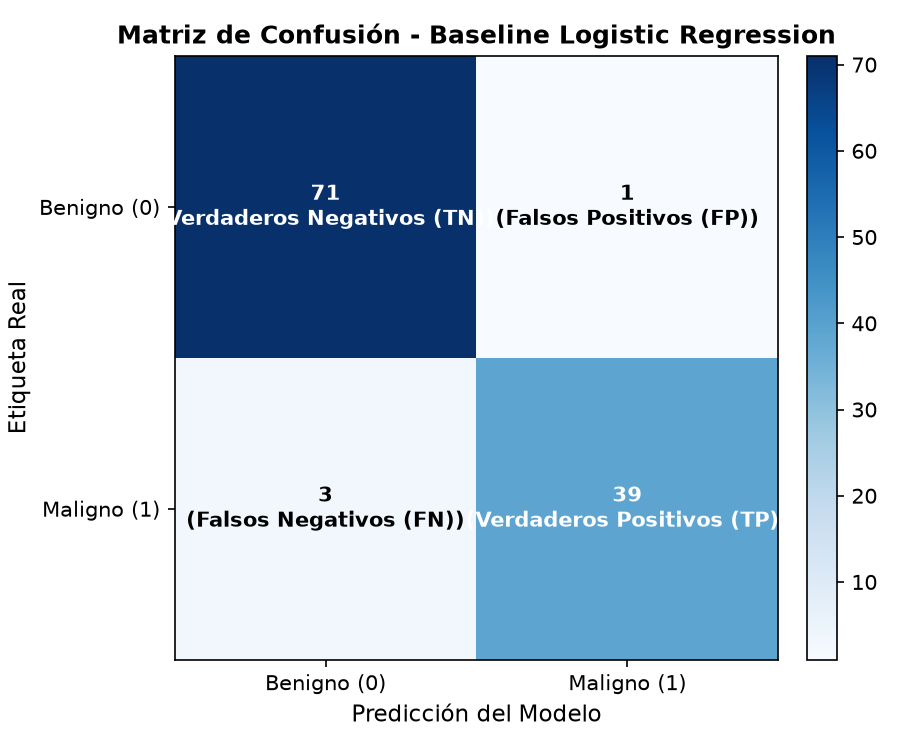

In [12]:
# Visualización de la Matriz de Confusión y Curva ROC
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusión
im = ax1.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax1.set_title('Matriz de Confusión', fontsize=12, fontweight='bold')
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
tick_marks = [0, 1]
ax1.set_xticks(tick_marks, ['Benigno (0)', 'Maligno (1)'])
ax1.set_yticks(tick_marks, ['Benigno (0)', 'Maligno (1)'])
thresh = cm.max() / 2.0
labels_names = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i, j]}\n({labels_names[i][j]})",
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=11, fontweight='bold')
ax1.set_ylabel('Etiqueta Real', fontsize=10)
ax1.set_xlabel('Predicción', fontsize=10)

# 2. Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
ax2.plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'Regresión Logística (AUC = {auc:.3f})')
ax2.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Azar (AUC = 0.500)')
ax2.set_xlim([-0.02, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=10)
ax2.set_ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=10)
ax2.set_title('Curva ROC', fontsize=12, fontweight='bold')
ax2.legend(loc="lower right")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Interpretación Detallada de los Resultados
1. **Desempeño Global:** El modelo baseline alcanza una exactitud del **96.49%** ($110$ casos clasificados correctamente de $114$), lo que confirma que las variables biométricas de FNA poseen un poder de discriminación muy alto.
2. **Evaluación Clínica de Errores:**
   - **Verdaderos Positivos (TP = 39):** De los $42$ casos malignos presentes en la prueba, el modelo detectó a tiempo a $39$.
   - **Falsos Negativos (FN = 3):** Tres pacientes con tumor maligno fueron clasificados erróneamente como benignos. Este es el error más costoso; en un entorno clínico, sugeriría ajustar el umbral de decisión de clasificación (por ejemplo, reducir el corte de probabilidad de $0.5$ a $0.35$) para elevar el Recall hacia el $100\%$, aun si se incrementan levemente los falsos positivos.
   - **Falsos Positivos (FP = 1):** Solamente $1$ caso benigno fue catalogado como maligno, lo que representa una especificidad casi perfecta del **98.61%**.
3. **Poder de Discriminación:** El **AUC de 0.9960** demuestra que con alta probabilidad el modelo asigna un puntaje de riesgo mayor a un paciente enfermo que a uno sano en prácticamente todo el espectro de corte.


---
## Paso 6: Registro del Experimento en MLflow Tracking

### Configuración del Experimento
Se utiliza **MLflow Tracking** conectado a la base de datos local SQLite (`sqlite:///mlflow.db`) para garantizar persistencia y reproducibilidad:
- **Experimento:** `Clasificacion_Cancer_Mama_Baseline`
- **Nombre de la Corrida:** `Baseline_LogisticRegression`
- **Elementos Registrados:**
  1. **Hiperparámetros y Metadatos:** Tipo de modelo, solver, parámetro $C$, tamaño de partición de prueba, semilla aleatoria, método de escalado y dimensiones.
  2. **Métricas de Evaluación:** Accuracy, Precision, Recall, Specificity, F1-Score, ROC-AUC, conteos de la matriz de confusión.
  3. **Artefactos del Modelo:**
     - El estimador entrenado de Scikit-Learn (`mlflow.sklearn.log_model`) con su firma de entrada (`input_example`).
     - Gráficas de EDA generadas (distribuciones, matriz de correlación, boxplots).
     - Gráficas de evaluación (matriz de confusión, curva ROC, coeficientes de importancia).
     - Bitácora de limpieza y reportes de texto.


In [13]:
# Configuración del servidor de tracking y experimento
mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENT_NAME = "Clasificacion_Cancer_Mama_Baseline"
mlflow.set_experiment(EXPERIMENT_NAME)

print(f"Tracking URI activo: {mlflow.get_tracking_uri()}")
print(f"Experimento configurado: {EXPERIMENT_NAME}")


Tracking URI activo: sqlite:///mlflow.db
Experimento configurado: Clasificacion_Cancer_Mama_Baseline


In [14]:
# Registro completo de la corrida en MLflow
with mlflow.start_run(run_name="Baseline_LogisticRegression") as run:
    run_id = run.info.run_id
    print(f"Corrida iniciada con Run ID: {run_id}")
    
    # 1. Registro de Parámetros
    mlflow.log_params({
        "modelo_tipo": "LogisticRegression",
        "dataset_nombre": "Breast Cancer Wisconsin Diagnostic",
        "dataset_fuente": "Kaggle / UCI Machine Learning Repository",
        "n_muestras_train": int(X_train.shape[0]),
        "n_muestras_test": int(X_test.shape[0]),
        "n_caracteristicas": int(X_train.shape[1]),
        "test_size": 0.20,
        "random_state": 42,
        "stratify": "True",
        "preprocesamiento": "StandardScaler",
        "solver": "lbfgs",
        "C": 1.0,
        "penalty": "l2",
        "max_iter": 1000
    })
    
    # 2. Registro de Métricas
    mlflow.log_metrics({
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1_score": float(f1),
        "roc_auc": float(auc),
        "specificity": float(specificity),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    })
    
    # 3. Tags Informativos
    mlflow.set_tags({
        "etapa": "baseline",
        "tarea": "clasificacion_binaria",
        "dominio": "salud_oncologia",
        "framework": "scikit-learn"
    })
    
    # 4. Registro de Artefactos (Gráficas y Reportes)
    mlflow.log_artifact("plots/confusion_matrix.png", artifact_path="graficas_evaluacion")
    mlflow.log_artifact("plots/roc_curve.png", artifact_path="graficas_evaluacion")
    mlflow.log_artifact("plots/feature_coefficients.png", artifact_path="graficas_evaluacion")
    mlflow.log_artifact("plots/eda_target_distribution.png", artifact_path="graficas_eda")
    mlflow.log_artifact("plots/eda_correlation_matrix.png", artifact_path="graficas_eda")
    mlflow.log_artifact("artifacts/reporte_evaluacion.txt", artifact_path="reportes")
    mlflow.log_artifact("artifacts/bitacora_limpieza.txt", artifact_path="reportes")
    
    # 5. Registro del Modelo Serializado con Firma de Inferencia
    input_sample = pd.DataFrame(X_test_scaled[:5], columns=X.columns)
    mlflow.sklearn.log_model(
        sk_model=baseline_model,
        name="modelo_baseline_logreg",
        input_example=input_sample
    )

print("\nRegistro en MLflow completado con éxito.")
print(f"Para inspeccionar la corrida ejecuta: mlflow ui --port 5000")


Corrida iniciada con Run ID: f8f45288a86347049be3e3dfeb858600
Registro en MLflow completado con éxito.
Para inspeccionar la corrida ejecuta: mlflow ui --port 5000


---
## Paso 7: Reflexión Crítica y Aplicación Profesional

### 1. ¿Qué mejoraría en este flujo aplicando prácticas de MLOps y por qué?
Aunque este flujo cubre satisfactoriamente el ciclo elemental de Machine Learning (ingesta, análisis exploratorio, limpieza documentada, entrenamiento baseline, evaluación e instrumentación con MLflow), en un entorno productivo empresarial presenta limitaciones arquitectónicas que deben subsanarse adoptando prácticas maduras de MLOps:

1. **Versionado Integral de Datos y Código (DVC + Git):**  
   En este ejercicio, los datos provienen de un archivo CSV local estático. En producción, las muestras de pacientes llegan de forma continua. La adopción de **DVC (Data Version Control)** acoplado a almacenamiento en la nube (AWS S3, Google Cloud Storage o Azure Blob Storage) permitiría ligar de manera inmutable el hash exacto del conjunto de datos con el commit del código y el `run_id` de MLflow, garantizando reproducibilidad científica auditable y rollback instantáneo.
2. **Validación Automática de Datos y Esquemas (Great Expectations / Pydantic):**  
   Actualmente la detección de nulos y tipos se ejecuta de forma manual e imperativa. Es crucial implementar contratos de datos automáticos (*Data Quality Gates*) que validen rangos fisiológicos plausibles (por ejemplo, que el radio celular no sea negativo o nulo) antes de disparar el pipeline de reentrenamiento, bloqueando fallos silenciosos en producción.
3. **Orquestación y Pipelines Modulares (Prefect / Kubeflow / Airflow):**  
   Sustituir la ejecución en un notebook monolítico por un pipeline orquestado en componentes desacoplados e idempotentes (ingesta $\to$ validación $\to$ transformación $\to$ entrenamiento $\to$ evaluación $\to$ registro). Cada paso puede ejecutarse en contenedores aislados con recursos optimizados (CPU/GPU).
4. **Gobernanza y Registro Formal de Modelos (MLflow Model Registry):**  
   Implementar etapas de ciclo de vida del modelo (`Staging`, `Production`, `Archived`) con control de accesos, aprobaciones por parte de especialistas clínicos y pruebas automáticas de compatibilidad antes de su promoción.
5. **Integración Continua y Despliegue Continuo (CI/CD con GitHub Actions):**  
   Automatizar pruebas unitarias sobre las funciones de limpieza, validación de regresión de métricas (verificar que el nuevo modelo supere al baseline actual en *Recall*) y empaquetado del artefacto en una imagen Docker expuesta a través de una API REST con **FastAPI**.
6. **Monitoreo en Producción y Detección de Deriva (Evidently AI / MLflow Tracing):**  
   En el diagnóstico clínico, los cambios en los equipos de microscopía o en la demografía de pacientes provocan **Data Drift** (deriva de covariables) y **Concept Drift** (cambio en la relación entre morfología y malignidad). El monitoreo continuo de métricas en tiempo real permite disparar reentrenamientos proactivos antes de que ocurran diagnósticos erróneos.

### 2. ¿Cómo se ven reflejados estos aprendizajes dentro de tu área profesional?
En el ejercicio profesional de la ingeniería de software, la arquitectura de datos y la inteligencia artificial, la adopción de MLOps representa el puente indispensable entre la experimentación académica y la entrega continua de valor empresarial confiable. Históricamente, más del 80% de las iniciativas de ciencia de datos fracasan o quedan relegadas a notebooks locales debido a la incapacidad de operar, versionar y monitorear modelos de manera sostenible (la conocida deuda técnica de Machine Learning descrita por Sculley et al.).

Dominar herramientas como MLflow y comprender el flujo integral de experimentación permite transformar modelos predictivos en servicios de software con **contratos estrictos de inferencia**, trazabilidad total para cumplimiento regulatorio y alta confiabilidad operativa. En sectores altamente regulados y de misión crítica como la medicina, las finanzas o la ciberseguridad, donde las decisiones algorítmicas impactan directamente vidas humanas o patrimonios económicos, la reproducibilidad y la trazabilidad no son características opcionales, sino imperativos éticos y legales. En mi perfil profesional, estos aprendizajes potencian la capacidad de liderar proyectos interdisciplinarios, comunicarse fluidamente con equipos de DevOps y MLOps, y diseñar arquitecturas de datos resilientes que garantizan que la inteligencia artificial se despliegue con seguridad, transparencia y excelencia técnica.

---
## Guía para Visualizar la Interfaz de MLflow y Tomar la Captura de Pantalla

Para visualizar el experimento registrado y tomar la captura solicitada para la entrega:

1. **Abre tu terminal en la raíz de este proyecto (`/home/argaalan/mlops-proyecto`) y ejecuta:**
   ```bash
   ./venv/bin/mlflow ui --port 5000
   ```
2. **Abre tu navegador web e ingresa a:**
   ```
   http://127.0.0.1:5000
   ```
3. **En la barra lateral izquierda:**
   - Selecciona el experimento: **`Clasificacion_Cancer_Mama_Baseline`**.
4. **En la vista principal de corridas:**
   - Observarás la corrida **`Baseline_LogisticRegression`** con su estado `FINISHED`.
   - Podrás ver las columnas de métricas: `accuracy` (0.965), `recall` (0.929), `precision` (0.975), `f1_score` (0.951) y `roc_auc` (0.996).
5. **Haz clic sobre la corrida `Baseline_LogisticRegression`:**
   - En la sección **Parameters** verás todos los hiperparámetros registrados (`C`, `solver`, `test_size`, etc.).
   - En la sección **Metrics** verás los valores detallados y la matriz de confusión.
   - En la sección **Artifacts** podrás desplegar las carpetas `graficas_eda/`, `graficas_evaluacion/`, `reportes/` y `modelo_baseline_logreg/` (donde se observa el modelo MLmodel de Scikit-Learn y su esquema de inferencia).
6. **Toma la captura de pantalla:**
   - Puedes tomar una captura de la tabla general del experimento comparando las métricas, o una captura del detalle de la corrida mostrando los parámetros y los artefactos desplegados.
